# Our 10-band models on a background patch of `estimate.fits`

A control for notebook 04. There, the companion is a faint blob near the noise floor, and the
models labelled part of it as red-rising, Kapton-like materials. Here we run the same steps on a
patch of the frame's faint background pixels instead: if the patch gets the same kind of labels,
those labels come from the normalisation and the noise, not from the companion. `object.fits`,
the true scene behind the file, confirms that the patch is background: it is zero there.

The patch is the brightest group of faint pixels left once the satellite and the companion are
removed. Notebook 03 explains the steps in more detail; here we keep the text to what changes.

1. **From the file to model input**: remove the satellite and the companion, find the patch, and
   convert its values to reflectance with the same readings and brightness rules as in notebook 03.
2. **The models on it**: what the 10 models predict, and how much that depends on the choices
   made in section 1.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import pvlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, hsv_to_rgb
from astropy.io import fits
from scipy import ndimage
from omegaconf import OmegaConf

ROOT = Path("..").resolve()                       # project root
sys.path.insert(0, str(ROOT))                     # the project's src (models, dataset)
from src.data_generation import ID_TO_NAME, N_CLASSES, SpectralLibraryWarning
from src.datasets.hsi import HSIDataset
from src.registry import build_model

warnings.simplefilter("ignore", SpectralLibraryWarning)  # flagged-band reports, see notebook 01

FITS = ROOT / "assets" / "new_input" / "estimate.fits"
TRUTH = ROOT / "assets" / "new_input" / "object.fits"   # the true scene behind it
MESSAGE_BANDS = [914.286, 800.000, 711.111, 640.000, 581.818, 533.333, 492.308, 457.143,
                 426.667, 400.000]           # nm, in the file's order (message.txt): red to blue

# logs: the project's logs on the cluster, or their sshfs mount on the Mac
LOGDIR = ROOT / "logs"
if not (LOGDIR / "estimate_10band").is_dir():
    LOGDIR = Path.home() / "_remote_data" / "satellites_remote" / "logs"
EXPDIR = LOGDIR / "estimate_10band"
config = OmegaConf.load(EXPDIR / "config.yaml")
data = HSIDataset(config.data.params)            # the generator and library the models saw
LAM = data.cfg.wavelengths_nm                    # band centres in training order: blue to red
assert np.allclose(LAM, sorted(MESSAGE_BANDS))

S1, S2 = "#2a78d6", "#eb6834"                                        # our simulator: blue, patch: orange
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8a8f", "#e4e4e2"  # text, ticks/labels, faint lines, grid
TRUE = "#00b050"                                                     # the true object (object.fits): green
# white background, then saturated material colours (golden-ratio hues), so fading shows
HUES = [((i * 0.618) % 1, 0.85, 0.95 if i % 2 else 0.7) for i in range(N_CLASSES - 1)]
MATERIALS = ListedColormap(["white", *(hsv_to_rgb(h) for h in HUES)])
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
})


def window(a, size, centre):
    # size x size pixels around centre, over the last two axes
    (y, x), h = centre, size // 2
    return a[..., y - h:y + h + 1, x - h:x + h + 1]


def show(ax, image, title, **kw):
    ax.imshow(image, interpolation="nearest", **kw)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=8.5)
    ax.spines[["top", "right"]].set_visible(True)


def outline(ax, mask):
    # the true object (object.fits) as a green line on a panel
    ax.contour(mask, levels=[0.5], colors=TRUE, linewidths=1)

/Users/ppopov1/miniconda3/envs/pile/lib/python3.12/site-packages/torch/cuda/__init__.py:65: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


---
## 1. Turning the patch into model input

### 1.1 Finding the patch

We flip the bands to blue-to-red as in notebook 03, then split the image into groups of touching
non-zero pixels. As in notebook 04, the satellite is the group with the brightest pixel and the
companion the group with the largest total value among the rest; we set both to zero. The patch is
the group with the largest total value among what is left, and its pixels are those above 5% of its
peak, the rule notebook 04 uses for the companion. We also print each band's share of the
values for the satellite, the companion and the rest of the frame.

The first figure shows the area on a log scale, with the satellite and the companion outlined, and
in green the true satellite and companion from `object.fits`, which is zero everywhere else; the
second shows each band in a 25×25 px window around the patch, all on one grey scale.

satellite 175 px and companion 190 px, removed | patch group: 91 px, 6.8e-05 of the satellite's total, 0.16 of the companion's
patch pixels: 76 px, rows 271 - 291 , cols 254 - 262 , centre (280, 258)
object.fits: 45 non-zero px, 0 of them in the patch group

share of the values per band:   400   427   457   492   533   582   640   711   800   914
                   satellite:  0.04  0.05  0.07  0.08  0.09  0.10  0.12  0.15  0.17  0.13
                   companion:  0.00  0.02  0.02  0.04  0.07  0.10  0.04  0.14  0.22  0.35
 rest of the frame (1762 px):  0.02  0.02  0.02  0.03  0.04  0.07  0.07  0.14  0.25  0.35


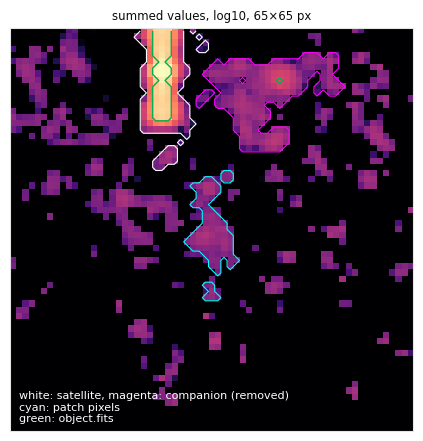

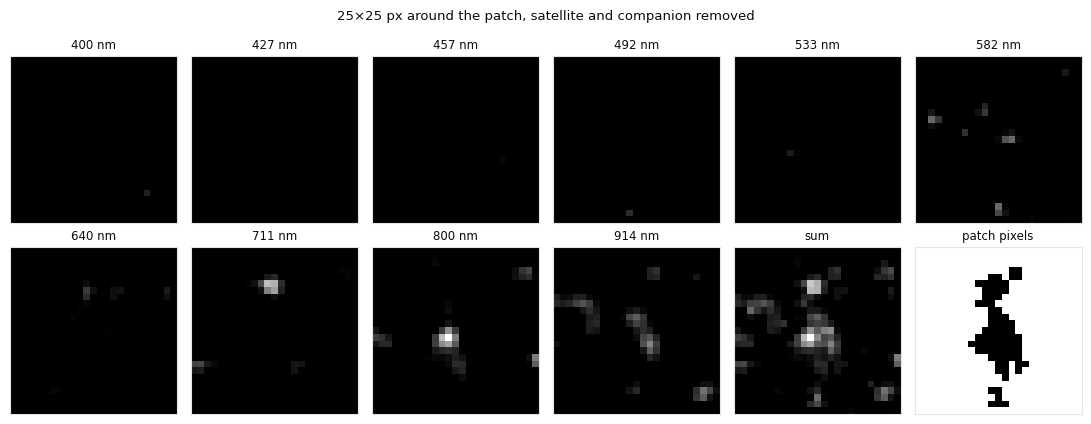

In [2]:
raw = fits.getdata(FITS).astype(float)          # (10, 512, 512), red -> blue
cube = raw[::-1].copy()                          # blue -> red, the models' order

# groups of touching non-zero pixels: the satellite, the companion, scattered faint pixels
groups, n = ndimage.label(cube.sum(0) > 0, structure=np.ones((3, 3)))
summed = cube.sum(0)
satellite = groups == groups[np.unravel_index(summed.argmax(), summed.shape)]
totals = ndimage.sum(summed, groups, range(1, n + 1))
totals[groups[satellite][0] - 1] = 0
companion = groups == totals.argmax() + 1
totals[totals.argmax()] = 0
patch = groups == totals.argmax() + 1             # the brightest group left: background
context = summed.copy()                          # before removing the objects, for the figure

cube[:, satellite | companion] = 0
total = cube.sum(0)
footprint = patch & (total > 0.05 * total[patch].max())
centre = tuple(int(round(v)) for v in ndimage.center_of_mass(total * footprint))
truth = fits.getdata(TRUTH).astype(float)[::-1]   # object.fits: the true scene
true_fg = truth.sum(0) > 0

ys, xs = np.nonzero(footprint)
print(f"satellite {satellite.sum()} px and companion {companion.sum()} px, removed | patch group: {patch.sum()} px,",
      f"{summed[patch].sum() / summed[satellite].sum():.1e} of the satellite's total,",
      f"{summed[patch].sum() / summed[companion].sum():.2f} of the companion's")
print("patch pixels:", footprint.sum(), "px, rows", ys.min(), "-", ys.max(), ", cols", xs.min(), "-", xs.max(),
      ", centre", centre)
print("object.fits:", true_fg.sum(), "non-zero px,", (true_fg & patch).sum(), "of them in the patch group")

# each band's share of the values: the satellite, the companion, every other non-zero pixel
rest = (summed > 0) & ~satellite & ~companion
print("\nshare of the values per band:", " ".join(f"{l:5.0f}" for l in LAM))
for name, m in (("satellite", satellite), ("companion", companion),
                (f"rest of the frame ({rest.sum()} px)", rest)):
    values = raw[::-1][:, m].sum(1)
    print(f"{name:>28s}:", " ".join(f"{v:5.2f}" for v in values / values.sum()))

# context: both objects on a log scale
fig, ax = plt.subplots(figsize=(4.5, 4.5))
show(ax, np.log10(window(context, 65, centre) + 1e-3), "summed values, log10, 65×65 px", cmap="magma")
ax.contour(window(satellite, 65, centre), levels=[0.5], colors="white", linewidths=0.8)
ax.contour(window(companion, 65, centre), levels=[0.5], colors="magenta", linewidths=0.8)
ax.contour(window(footprint, 65, centre), levels=[0.5], colors="cyan", linewidths=0.8)
outline(ax, window(true_fg, 65, centre))
ax.text(1, 63, "white: satellite, magenta: companion (removed)\ncyan: patch pixels\ngreen: object.fits",
        color="white", fontsize=8)
fig.tight_layout()

VIEW = 25                                        # px, side of the windows below
fig, axes = plt.subplots(2, 6, figsize=(11, 4.4))
vmax = window(cube, VIEW, centre).max()
for b, ax in enumerate(axes.flat[:10]):
    show(ax, window(cube[b], VIEW, centre), f"{LAM[b]:.0f} nm", cmap="gray", vmin=0, vmax=vmax)
show(axes.flat[10], window(total, VIEW, centre), "sum", cmap="gray")
show(axes.flat[11], window(footprint, VIEW, centre), "patch pixels", cmap="gray_r")
fig.suptitle(f"{VIEW}×{VIEW} px around the patch, satellite and companion removed", fontsize=9.5)
fig.tight_layout()

### 1.2 The sunlight

The same solar spectrum as in notebook 03 (ASTM E-490, from `pvlib`), at the 10 band centres.

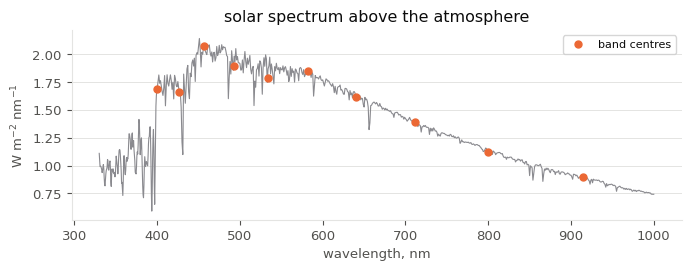

In [3]:
solar = pvlib.spectrum.get_reference_spectra(standard="ASTM G173-03")["extraterrestrial"]  # W m-2 nm-1
E = np.interp(LAM, solar.index, solar.values)

fig, ax = plt.subplots(figsize=(7, 2.8))
grid = solar.loc[330:1000]
ax.plot(grid.index, grid.values, color=MUTED, lw=0.8)
ax.plot(LAM, E, "o", color=S2, ms=5, label="band centres")
ax.set(xlabel="wavelength, nm", ylabel="W m$^{-2}$ nm$^{-1}$", title="solar spectrum above the atmosphere")
ax.grid(axis="y"); ax.legend(fontsize=8)
fig.tight_layout()

### 1.3 From values to reflectance

The same four readings as in notebook 03 (`V`, `V / E`, `V / (E·Δλ)`, `V / (E·Δλ·λ)`), now applied
to the patch. As there, we compare the shape of the patch's mean spectrum under each
reading with the spectra of our 46 materials, each curve divided by its own mean.

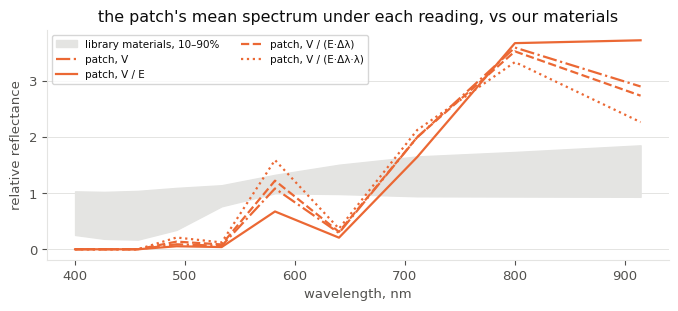

In [4]:
DLAM = LAM ** 2 / 6400                            # band width, nm, for centres at 6400/n nm
READINGS = {                                      # what each band's values are divided by
    "V": np.ones_like(LAM),
    "V / E": E,
    "V / (E·Δλ)": E * DLAM,
    "V / (E·Δλ·λ)": E * DLAM * LAM,
}
library = np.stack([m.pristine for m in data.library.materials.values()])
library = library / library.mean(1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.fill_between(LAM, *np.percentile(library, [10, 90], axis=0), color=GRID,
                label="library materials, 10–90%")
for (name, divisor), ls in zip(READINGS.items(), ("-.", "-", "--", ":")):
    spectrum = (cube[:, footprint] / divisor[:, None]).mean(1)
    ax.plot(LAM, spectrum / spectrum.mean(), color=S2, ls=ls, lw=1.6, label=f"patch, {name}")
ax.set(xlabel="wavelength, nm", ylabel="relative reflectance",
       title="the patch's mean spectrum under each reading, vs our materials")
ax.grid(axis="y"); ax.legend(fontsize=7.5, ncol=2)
fig.tight_layout()

Like the companion's in notebook 04, the patch's mean spectrum fits none of our materials: under
every reading it is near zero below 550 nm, dips at 640 nm and rises steeply to 800 nm. The band
shares printed in section 1.1 show the same red lean for all the frame's faint pixels, and the
companion's shares are close to theirs, unlike the satellite's. As `object.fits` is zero at all of
these pixels, the red lean comes from the reconstruction; notebook 04 shows that the companion's
true spectrum is strong in the blue. We keep `V / E` as the default; section 2.2 runs the models
under every reading.

In [5]:
READING = "V / E"


def reflectance(scale, reading=None):
    # the cube as reflectance under a reading, times a brightness scale
    return cube / READINGS[reading or READING][:, None, None] * scale

### 1.4 Brightness

The same three rules for the factor `k` as in notebook 03, applied to the patch's pixels:
**max = 1** (default), **median match** and **95% match**, the last two against the satellite
pixels of 500 scenes from our simulator.

Below, left: per band, our simulated satellite scenes next to the patch's values at the
default `k`. Right: the patch's pixel brightness under each rule.

max = 1     : patch brightness median 0.017, max value 1.00
median match: patch brightness median 0.341, max value 19.51
95% match   : patch brightness median 0.183, max value 10.47
our simulator, satellites: brightness median 0.341, max value 1.03


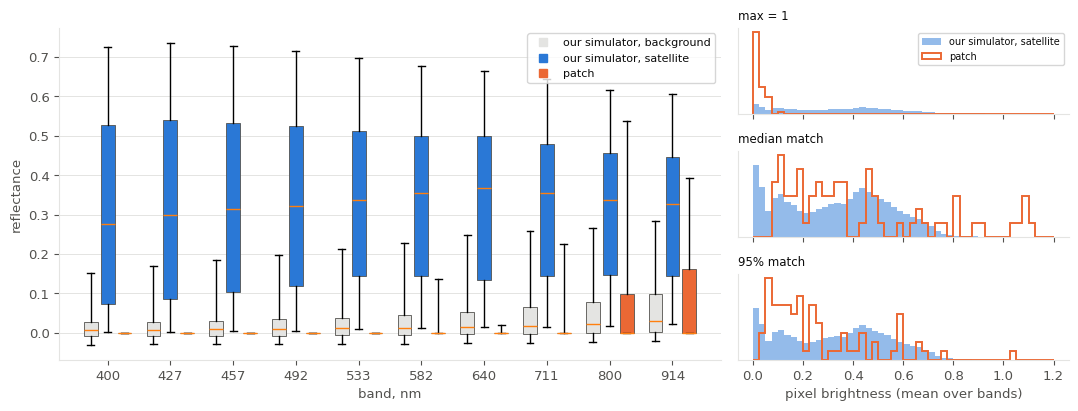

In [6]:
records = data.split("test_satellite")[(0, range(500))].values()
gen_cubes = torch.stack([r["input"] for r in records]).numpy()
gen_masks = torch.stack([r["label"] for r in records]).numpy()
gen_fg = gen_cubes.transpose(1, 0, 2, 3)[:, gen_masks > 0]       # [bands, satellite pixels]
gen_bg = gen_cubes.transpose(1, 0, 2, 3)[:, gen_masks == 0]


def scale_rules(reading=None):
    # k under each rule, for the patch's pixels under a reading
    brightness = reflectance(1.0, reading)[:, footprint].mean(0)
    reference = gen_fg.mean(0)
    return {"max = 1": 1 / reflectance(1.0, reading)[:, footprint].max(),
            "median match": np.median(reference) / np.median(brightness),
            "95% match": np.percentile(reference, 95) / np.percentile(brightness, 95)}


SCALES = scale_rules()
SCALE = SCALES["max = 1"]
obj = reflectance(SCALE)[:, footprint]
for name, scale in SCALES.items():
    values = reflectance(scale)[:, footprint]
    print(f"{name:12s}: patch brightness median {np.median(values.mean(0)):.3f}, max value {values.max():.2f}")
print(f"our simulator, satellites: brightness median {np.median(gen_fg.mean(0)):.3f}, max value {gen_fg.max():.2f}")

fig = plt.figure(figsize=(11, 4.2))
grid = fig.add_gridspec(len(SCALES), 2, width_ratios=[2, 1])
ax = fig.add_subplot(grid[:, 0])
x = np.arange(len(LAM))
for values, offset, color, label in ((gen_bg, -0.27, GRID, "our simulator, background"),
                                     (gen_fg, 0, S1, "our simulator, satellite"),
                                     (obj, 0.27, S2, "patch")):
    parts = ax.boxplot(list(values), positions=x + offset, widths=0.22, whis=(5, 95),
                       showfliers=False, patch_artist=True)
    for box in parts["boxes"]:
        box.set(facecolor=color, edgecolor=INK2, lw=0.6)
    ax.plot([], [], "s", color=color, label=label)
ax.set(xticks=x, xticklabels=[f"{l:.0f}" for l in LAM], xlabel="band, nm", ylabel="reflectance")
ax.grid(axis="y"); ax.legend(fontsize=8)

# one histogram per brightness rule, stacked on a shared x axis
bins = np.linspace(0, 1.2, 49)
hists = []
for r, (name, scale) in enumerate(SCALES.items()):
    hx = fig.add_subplot(grid[r, 1], sharex=hists[0] if hists else None)
    hx.hist(gen_fg.mean(0), bins, density=True, color=S1, alpha=0.5, label="our simulator, satellite")
    hx.hist(reflectance(scale)[:, footprint].mean(0), bins, density=True, histtype="step", color=S2,
            lw=1.4, label="patch")
    hx.set(yticks=[]); hx.set_title(name, fontsize=8.5, loc="left")
    hx.tick_params(labelbottom=r == len(SCALES) - 1)
    hists.append(hx)
hists[-1].set_xlabel("pixel brightness (mean over bands)")
hists[0].legend(fontsize=7)
fig.tight_layout()

The images under each setting: the patch averaged over the 10 bands, in the 21×21 px window
the models get in section 2, for each reading (rows) and brightness rule (columns), on a shared 0–1
grey scale; the title gives the brightest value. The bottom row shows three of our simulated
satellite scenes on the same scale.

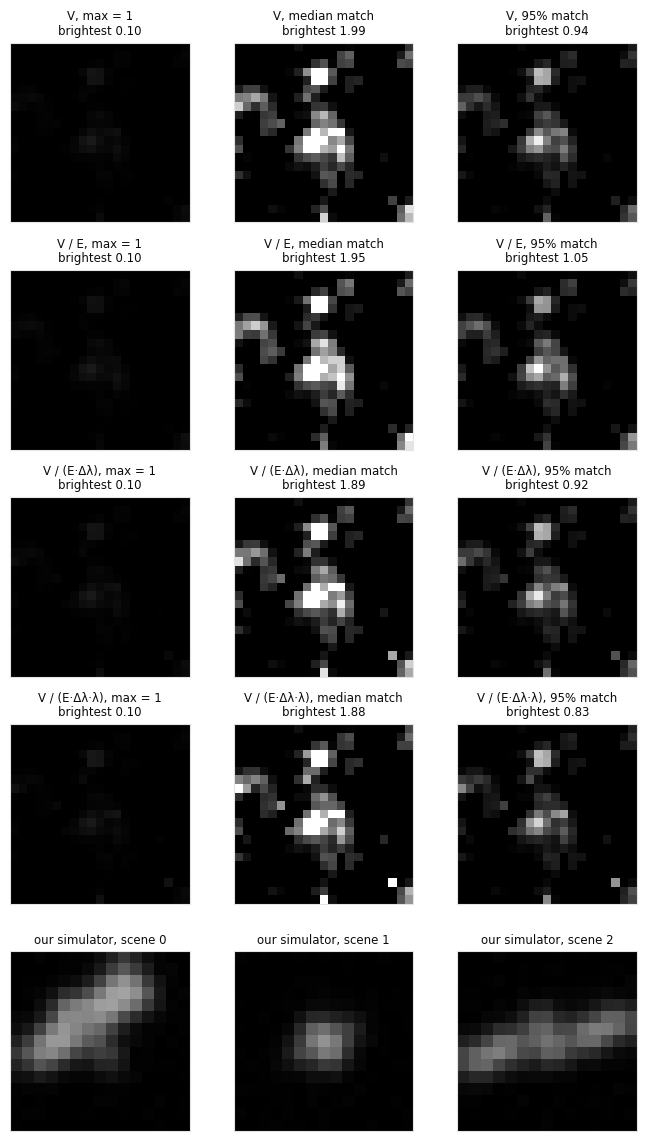

In [7]:
CROP = 21                                        # px, the models' window
rules = list(SCALES)
fig, axes = plt.subplots(len(READINGS) + 1, len(rules), figsize=(2.3 * len(rules), 2.3 * (len(READINGS) + 1)))
for r, reading in enumerate(READINGS):
    for col, (rule, scale) in enumerate(scale_rules(reading).items()):
        image = window(reflectance(scale, reading), CROP, centre).mean(0)
        show(axes[r, col], image, f"{reading}, {rule}\nbrightest {image.max():.2f}", cmap="gray", vmin=0, vmax=1)
for col in range(len(rules)):
    show(axes[-1, col], gen_cubes[col].mean(0), f"our simulator, scene {col}", cmap="gray", vmin=0, vmax=1)
fig.tight_layout()

---
## 2. Applying the models to the patch

Here we run all 10 models on the patch, converted with the default reading (`V / E`) and
brightness (max = 1). Each model gets a 21×21 px window around the patch, with the satellite and
the companion removed, and labels every pixel as background or one of 46 materials; we combine
the 10 labelings by majority vote.

In the figure, the top row shows the band-summed values, the patch pixels and the majority vote;
the rows below show each model's labels. `object.fits` is zero over the whole window.

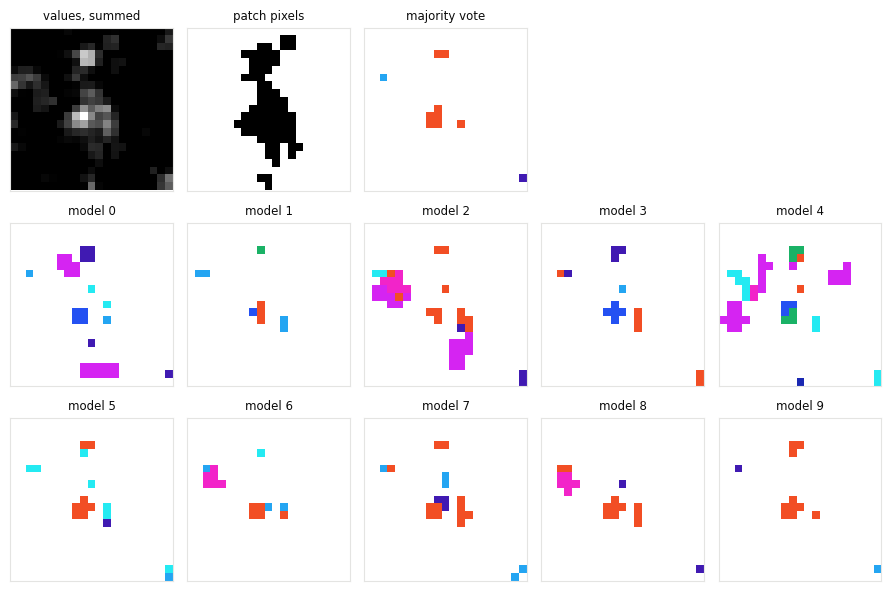

In [8]:
models = []
for rundir in sorted(EXPDIR.glob("run_*"), key=lambda p: int(p.name.split("_")[1])):
    model = build_model(config)
    model.load_state_dict(torch.load(rundir / "model.best.pth", map_location="cpu"))
    models.append(model.eval())


def predict(x):
    # every run's labels for a [bands, H, W] input: [runs, H, W]
    with torch.no_grad():
        t = torch.from_numpy(x[None]).float()
        return torch.stack([m(t).argmax(1)[0] for m in models]).numpy()


def vote(preds):
    # majority label per pixel
    return torch.from_numpy(preds).mode(0).values.numpy()


preds = predict(window(reflectance(SCALE), CROP, centre))
labels = vote(preds)
fp = window(footprint, CROP, centre)

fig, axes = plt.subplots(3, 5, figsize=(9, 6))
show(axes[0, 0], window(total, CROP, centre), "values, summed", cmap="gray")
show(axes[0, 1], fp, "patch pixels", cmap="gray_r")
show(axes[0, 2], labels, "majority vote", cmap=MATERIALS, vmin=0, vmax=N_CLASSES - 1)
axes[0, 3].axis("off"); axes[0, 4].axis("off")
for r, ax in enumerate(axes[1:].flat):
    show(ax, preds[r], f"model {r}", cmap=MATERIALS, vmin=0, vmax=N_CLASSES - 1)
fig.tight_layout()

### 2.1 Spectra of the common predicted materials

For the materials the vote gives most often on the patch, we plot the spectra of the pixels
labelled with them (orange) next to the material's measured spectra, pristine and irradiated
(black).

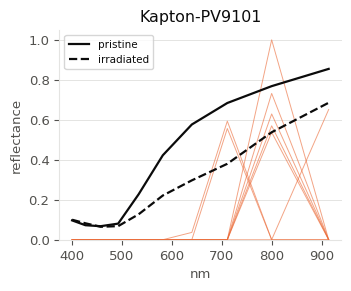

In [9]:
top = [i for i in pd.Series(labels[fp]).value_counts().index if i][:3]  # most common materials
assert top, "no patch pixel got a material"
fig, axes = plt.subplots(1, len(top), figsize=(3.6 * len(top), 3), squeeze=False)
image = window(reflectance(SCALE), CROP, centre)
for ax, i in zip(axes[0], top):
    for spectrum in image[:, fp & (labels == i)].T:
        ax.plot(LAM, spectrum, color=S2, lw=0.7, alpha=0.6)
    material = data.library.materials[ID_TO_NAME[i]]
    ax.plot(LAM, material.pristine, color=INK, lw=1.6, label="pristine")
    if material.irradiated is not None:
        ax.plot(LAM, material.irradiated, color=INK, lw=1.6, ls="--", label="irradiated")
    ax.set(title=ID_TO_NAME[i], xlabel="nm", ylim=(0, None)); ax.grid(axis="y")
axes[0, 0].set_ylabel("reflectance"); axes[0, 0].legend(fontsize=7.5)
fig.tight_layout()

### 2.2 How much do the reading and the brightness matter?

We repeat the prediction for every reading and brightness rule, in the same 21×21 px window. Rows
are readings and columns are brightness rules; each panel shows the majority vote. Ideally,
everything stays white: `object.fits` is zero over the whole window.

In [10]:
assert not window(true_fg, CROP, centre).any()   # object.fits is zero over the window


def scores(v):
    # one setting's vote; everything in the window is background in object.fits
    return {"window labelled as material": (v > 0).mean()}


results = []                                     # (setting, vote)
for reading in READINGS:
    for rule, scale in scale_rules(reading).items():
        x = window(reflectance(scale, reading), CROP, centre)
        results.append(({"reading": reading, "brightness": rule, "window": CROP}, vote(predict(x))))
for size in (33, 65, 129, 512):
    x = reflectance(SCALE)
    frame, at = (x, centre) if size == 512 else (window(x, size, centre), (size // 2, size // 2))
    setting = {"reading": READING, "brightness": "max = 1", "window": size}
    results.append((setting, vote(window(predict(frame), CROP, at))))

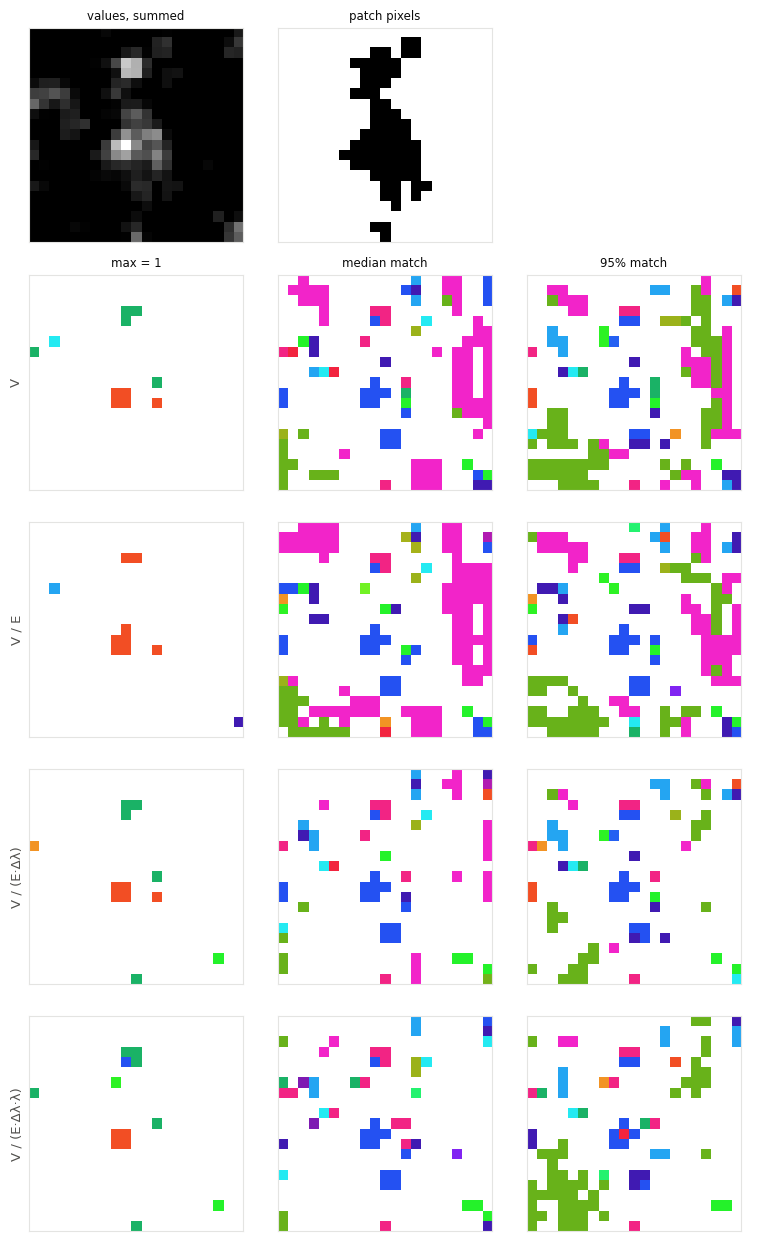

In [11]:
rules = list(SCALES)
found = {(s["reading"], s["brightness"]): v for s, v in results if s["window"] == CROP}
fig, axes = plt.subplots(1 + len(READINGS), len(rules), figsize=(2.6 * len(rules), 2.5 * (1 + len(READINGS))))

# top row: the input
show(axes[0, 0], window(total, CROP, centre), "values, summed", cmap="gray")
show(axes[0, 1], fp, "patch pixels", cmap="gray_r")
axes[0, 2].axis("off")

# one row per reading, one column per brightness rule
for r, reading in enumerate(READINGS, start=1):
    for col, rule in enumerate(rules):
        show(axes[r, col], found[(reading, rule)], rule if r == 1 else "", cmap=MATERIALS, vmin=0,
             vmax=N_CLASSES - 1)
    axes[r, 0].set_ylabel(reading, fontsize=9.5)
fig.tight_layout()

The same settings in numbers: the share of the window labelled as a material (ideally 0).

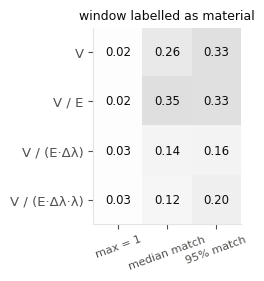

In [12]:
table = pd.DataFrame([{**s, **scores(v)} for s, v in results if s["window"] == CROP])
(column,) = scores(labels)
values = table.pivot(index="reading", columns="brightness", values=column).loc[list(READINGS), rules]
fig, ax = plt.subplots(figsize=(4.2, 2.9))
ax.imshow(values.to_numpy(), cmap="Greys", vmin=0, vmax=1.6)
for (i, j), value in np.ndenumerate(values.to_numpy()):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8.5)
ax.set_xticks(range(len(rules)), rules, fontsize=8, rotation=20)
ax.set_yticks(range(len(READINGS)), list(READINGS))
ax.set_title(column, fontsize=9)
fig.tight_layout()

### 2.3 Does the window size matter?

As in notebook 03, we run the models on larger windows (satellite and companion removed) at the
default reading and brightness, and compare the 21×21 px centre of each result with the default
window. The titles give the share of the window labelled as a material.

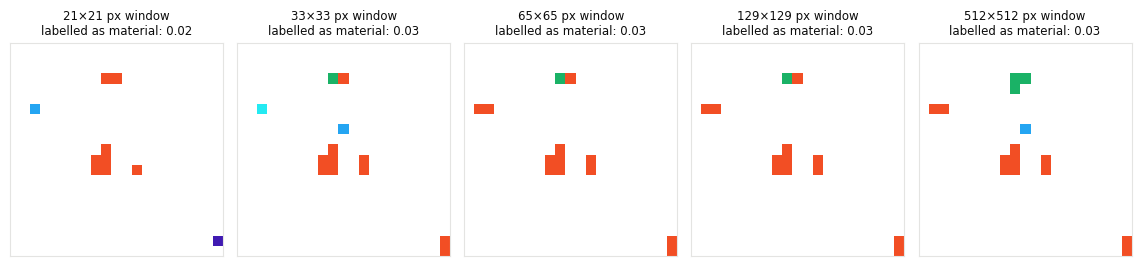

In [13]:
windows = [(s, v) for s, v in results if (s["reading"], s["brightness"]) == (READING, "max = 1")]
fig, axes = plt.subplots(1, len(windows), figsize=(2.3 * len(windows), 2.8))
for ax, (s, v) in zip(axes, windows):
    (material,) = scores(v).values()
    show(ax, v, f"{s['window']}×{s['window']} px window\nlabelled as material: {material:.2f}", cmap=MATERIALS,
         vmin=0, vmax=N_CLASSES - 1)
fig.tight_layout()

---
## Result

`object.fits` is zero over this whole window, so every material label here is wrong. At the
defaults, the vote labels 2% of the window as a material, mostly Kapton on the patch's brightest
pixels; under the median and 95% match rules, 12–35%. In notebook 04, the same share for the
companion's window is 6% at the defaults and 23–78% under the other two rules: its blob is larger
and brighter and more of it gets labelled, but only one of its pixels is real. So here the Kapton
labels can only come from the brightness scaling and the reconstruction's red-leaning spill.